## 랭그래프를 활용한 멀티에이전트 RAG 만들기
### 기존 RAG의 한계
- 일반적인 RAG 파이프라인은 '질문 입력 → 벡터 DB 검색 → 답변 생성'의 일방향(Linear) 체인 구조로 작동.
- 잘못된 문서가 검색되면 AI가 잘못된 정보를 기반으로 환각(Hallucination)을 일으킬 수 있음.
- 복잡한 질문을 던질경우 한 번의 검색만으로는 상충되거나 흩어진 정보를 제대로 종합할 수 없음.
- 답변이 마음에 들지 않을때 이전 단계로 돌아가 다시 검색하는 유연한 대처가 불가능함.
### 멀티에이전트(multi-agent)란?
- 하나의 거대한 AI가 모든 일을 처리하는 대신, 특정 역할과 전문성을 가진 여러 개의 독립적인 AI(에이전트)들이 협력하거나 경쟁하며 복잡한 문제를 해결하는 구조.

### 실습
- 09장에서 사용했던 PDF파일을 재사용한다. 


In [1]:
from glob import glob 

for g in glob('../chap09/data/*.pdf'):
    print(g)

../chap09/data\2040_seoul_plan.pdf
../chap09/data\OneNYC_2050_Strategic_Plan.pdf


- PDF 파일을 텍스트로 읽고 청크 단위로 텍스트를 잘라 리스트로 담아 반환하는 함수 만들기.

In [1]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

def read_pdf_and_split_text(pdf_path, chunk_size=1000, chunk_overlap=100):
    """
    주어진 PDF 파일을 읽고 텍스트를 분할합니다.
    매개변수:
        pdf_path (str): PDF 파일의 경로.
        chunk_size (int, 선택적): 각 텍스트 청크의 크기. 기본값은 1000입니다.
        chunk_overlap (int, 선택적): 청크 간의 중첩 크기. 기본값은 100입니다.
    반환값:
        list: 분할된 텍스트 청크의 리스트.
    """
    print(f"PDF: {pdf_path} -----------------------------")

    pdf_loader = PyPDFLoader(pdf_path)
    data_from_pdf = pdf_loader.load()

    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size, chunk_overlap=chunk_overlap
    )

    splits = text_splitter.split_documents(data_from_pdf)
    
    print(f"Number of splits: {len(splits)}\n")
    return splits


C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_32852\2190706148.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


- 청크를 임베딩해서 크로마DB에 저장.
- 시간과 비용 절약을 위해 09장에서 만든 폴더 사용.

In [6]:
from dotenv import load_dotenv
import os

load_dotenv()
api_key = os.getenv('OPENAI_API_KEY')


from langchain_openai import OpenAIEmbeddings
from langchain_chroma import Chroma
import os

##### Vectorstore 설정 #####
embedding = OpenAIEmbeddings(model='text-embedding-3-large')

persist_directory='../chap09/chroma_store'

if os.path.exists(persist_directory):
    print("Loading existing Chroma store")
    vectorstore = Chroma(
        persist_directory=persist_directory, 
        embedding_function=embedding
    )

retriever = vectorstore.as_retriever(search_kwargs={"k": 5})

chunks = retriever.invoke("서울 온실가스 저감 계획")

for chunk in chunks:
    print(chunk.metadata)
    print(chunk.page_content)

Loading existing Chroma store
{'pdfversion': '1.4', 'page_label': '64', 'moddate': '2024-12-12T18:16:11+09:00', 'creator': 'Hwp 2020 11.0.0.5178', 'source': 'F:/ksol927_ai_study/StudyRepo/learn_doit_llm_agent/chap09/data/2040_seoul_plan.pdf', 'author': 'SI', 'creationdate': '2024-12-12T18:16:11+09:00', 'producer': 'Hancom PDF 1.3.0.542', 'total_pages': 205, 'page': 63}
56 제2장 미래상과 목표
6. 미래위기를 준비하는, ‘탄소중립 안전도시 구축’
1) 배경
전(全) 지구적인 기후변화에 대응하기 위한 대도시 차원의 대응 필요
Ÿ 서울시 2017년 온실가스 배출량은 46,685천 톤CO2eq로 2005년 배출량에 비해 5.6%(276만 톤
CO2eq) 감소하였으며, 서울의 1인당 온실가스 배출량은 4.7CO2eq로 국가의 13.8톤CO2eq에 비
해 낮은 수준이다. 또한 2014년 기준 서울의 1인당 온실가스 배출량은 4.5CO2eq로 세계 주요 도시
에 비해 낮은 수준을 보인다.7)
[그림 2-26] 세계 주요 도시 1인당 온실가스 배출량
   자료: World Bank, 2014
Ÿ 그럼에도 불구하고, 기후변화 문제는 21세기에 전 지구적으로 가장 위중한 영향을 미칠 것으로 예
상되는바, 탄소중립과 기후위기 대응은 국제·국가·도시의 핵심 정책으로 다루어져야 한다.
Ÿ 파리협정(2015) 이후, 우리나라를 비롯한 미국, 유럽연합 등 세계 136개국이 탄소중립을 선언하였
으며, 서울시를 비롯한 뉴욕, 런던 등과 같은 많은 글로벌 도시에서 탄소중립을 시정의 핵심과제로 
추진 중이다.
Ÿ 우리나라는 2020년 ‘한국판 그린뉴딜’을 발표하며 공식적으로 2050 탄소중립을 선언하였

- 언어 모델 설정.

In [7]:
from langchain_openai import ChatOpenAI

# 모델 초기화
model = ChatOpenAI(model="gpt-5.6-luna")
model.invoke('안녕하세요!')

AIMessage(content='안녕하세요! 무엇을 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 14, 'prompt_tokens': 9, 'total_tokens': 23, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.6-luna', 'system_fingerprint': None, 'id': 'chatcmpl-Ea1IxdQu0VmKJhBoZ66Kan1GbzbhI', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a14aa2-8d9b-70f1-9073-15471b3d0b17-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 9, 'output_tokens': 14, 'total_tokens': 23, 'input_token_details': {'audio': 0, 'cache_read': 0, 'cache_creation': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

### 라우터
- 멀티에이전트 시스템에서 라우터(Router)는 사용자의 입력이나 현재 시스템의 상태를 분석하여, "이 작업은 어떤 전문 에이전트(Agent)가 처리하는 것이 가장 좋을지" 판단하고 길을 안내하는 의사결정 레이어.
#### 유형
- LLM 기반 라우터 (지능형)
    - 라우터 자체에 가벼운 LLM을 탑재합니다. LLM에게 "다음 질문이 수학, 코딩, 번역 중 어디에 속하는지 분류해줘"라는 프롬프트를 주어 동적으로 경로를 결정.
- 규칙 기반 라우터 (Rule-based)
    - 특정 키워드나 정규식(Regex)을 이용합니다.
- 하이브리드 라우터
    - 1차적으로 키워드를 검사하고, 애매한 문장일 때만 LLM을 호출하여 분류하는 효율적인 방식.

#### 주요 패턴
- 단일 라우팅
    - 질문을 분석해 단 하나의 가장 적합한 에이전트에게만 토스하고 끝.
- 병렬 라우팅
    - 사용자가 복합적인 질문을 했을때 라우터가 이를 쪼개어 여러 에이전트에 동시로 업무를 지시 후 결과를 취합.
- 조건부 엣지 기반 라우팅
    - 랭그래프의 핵심 기능, 작업 노드가 끝난 후 상태 값에 따라 다음 목적지를 동적으로 바꿈.
    - ex. 답변 품질 점수가 70점 미만이면 수정 에이전트로, 70점 이상이면 종료로 라우팅.


In [8]:
# Router 설정
from langchain_core.prompts import ChatPromptTemplate
from typing import Literal # 문자열 리터럴 타입을 지원하는 typing 모듈의 클래스
from pydantic import BaseModel, Field

# Data model
class RouteQuery(BaseModel):
    """사용자 쿼리를 가장 관련성이 높은 데이터 소스로 라우팅합니다."""
    
    datasource: Literal["vectorstore", "casual_talk"] = Field(
        ...,
        description="""
        사용자 질문에 따라 casual_talk 또는 vectorstore로 라우팅합니다.
        - casual_talk: 일상 대화를 위한 데이터 소스. 사용자가 일상적인 질문을 할 때 사용합니다.
        - vectorstore: 사용자 질문에 답하기 위해 RAG로 vectorstore 검색이 필요한 경우 사용합니다.
        """,
    )

In [9]:
# 특정 모델을 structured output (구조화된 출력)과 함께 사용하기 위해 설정
structured_llm_router = model.with_structured_output(RouteQuery)

router_system = """
당신은 사용자의 질문을 vectorstore 또는 casual_talk으로 라우팅하는 전문가입니다.
- vectorstore에는 서울, 뉴욕의 발전계획과 관련된 문서가 포함되어 있습니다. 이 주제에 대한 질문에는 vectorstore를 사용하십시오.
- 사용자의 질문이 일상 대화에 관련된 경우 casual_talk을 사용하십시오.
"""

# 시스템 메시지와 사용자의 질문을 포함하는 프롬프트 템플릿 생성
route_prompt = ChatPromptTemplate.from_messages([
    ("system", router_system),
    ("human", "{question}"),
])

# 라우터 프롬프트와 구조화된 출력 모델을 결합한 객체
question_router = route_prompt | structured_llm_router

In [10]:
print(
    question_router.invoke({
        "question": "서울 온실가스 저감 계획은 무엇인가요?"
    })
)

print(question_router.invoke({"question": "잘 지냈어?"}))

datasource='vectorstore'
datasource='casual_talk'


#### 관련 있는 청크만 필터링
- 리트리버가 가져온 청크 중 질문과 관련 없는 청크를 삭제. 
- 프롬프트로 문서의 관련성을 판단하는 방법을 작성하고 판단 결과를 Yes or No로 제한.

In [11]:
from langchain_core.prompts import PromptTemplate

class GradeDocuments(BaseModel):
    """검색된 문서가 질문과 관련성 있는지 yes 또는 no로 평가합니다."""

    binary_score: Literal["yes", "no"] = Field(
        description="문서가 질문과 관련이 있는지 여부를 'yes' 또는 'no'로 평가합니다."
    )

structured_llm_grader = model.with_structured_output(GradeDocuments)

In [12]:
grader_prompt = PromptTemplate.from_template("""
당신은 검색된 문서가 사용자 질문과 관련이 있는지 평가하는 평가자입니다. \n 
문서에 사용자 질문과 관련된 키워드 또는 의미가 포함되어 있으면, 해당 문서를 관련성이 있다고 평가하십시오. \n
엄격한 테스트가 필요하지 않습니다. 목표는 잘못된 검색 결과를 걸러내는 것입니다. \n
문서가 질문과 관련이 있는지 여부를 나타내기 위해 'yes' 또는 'no'로 이진 점수를 부여하십시오.
                                             
Retrieved document: \n {document} \n\n 
User question: {question}
""")

retrieval_grader = grader_prompt | structured_llm_grader
question = "서울시 자율주행 관련 계획"
documents = retriever.invoke(question)

for doc in documents:
    print(doc)

page_content='54 제2장 미래상과 목표
5. 기술발전에 선제적 대응, ‘미래교통 인프라 구축’
1) 배경
미래교통수단 도입에 따른 도시 활동 변화 및 공간구조 재편 대비
Ÿ 빠르게 진화하는 미래 신 교통수단은 도시공간에 새로운 변화를 일으킬 것이며, 도시 내 이동패턴의 
변화를 가져올 것으로 예측된다. 이러한 점을 고려하여 도시 내 다양한 통행행태가 공존하는 포용적인 
교통체계 구축을 준비해야 한다.
미래교통수단 정착을 위한 도시 인프라 확충지원 필요
Ÿ 기존에 없던 새로운 교통은 통상 인프라 구축에 많은 시간이 소요되기 때문에 교통수단이 도입된 이
후에 준비하기보다는 개발단계에서부터 이를 지원하기 위한 교통인프라 구축 구상이 요구되며, 새
로운 도시 인프라 확충에 대한 도시계획적 지원이 필요하다.
2) 추진전략
자율주행 자동차 본격 운영 체계 구축
Ÿ 자율주행은 현재 제일 가시화되고 있는 미래 교통기술로 시장의 주도권을 확보하기 위해 각국의 
노력이 집중되고 있다. 단계적으로 2030년까지 간선도로급 이상 도로에서 운영할 수 있는 도로 
인프라 환경을 조성하고, 2040년까지 서울 전역 자율주행 운행 환경 구축을 목표로 한다.
- 2040년까지 서울 전역 자율주행차량의 운행 환경을 구축하고 수송 분담률 10%를 달성
서울형 도심 항공교통 기반 마련 및 터미널 확충
Ÿ 도심에서 김포공항까지 시범노선을 운영하는 등 상용화 노선을 확보하고, 장기적으로 한강, 지천 등 
주요 수변 공간 중심으로 광역노선을 확보한다. 또한 UAM 인프라 확보를 위한 인센티브 및 도시계
획적인 지원 방안도 함께 검토한다.
- UAM 시범노선을 운영하고, 한강 등 주요 수변 공간 중심에 단계적 광역노선을 확장
서울 전역에 모빌리티 허브 구축
Ÿ 도심 및 광역거점에 서울 내부와 외부의 연계를 위한 미래 교통과 기존 교통을 연결하는 시설을 도
입한다. 또한 교통뿐 아니라 공공서비스, 물류, 상업 등 다양한 기능들이 복합적으로 제공되는 지
역 거점 모빌리티 허브를 서울 전역에 도

In [13]:
filtered_docs = []

for i, doc in enumerate(documents):
    print(f"Document {i + 1}:")
    is_relevant = retrieval_grader.invoke({"question": question, "document": doc.page_content})
    print(is_relevant)
    print(doc.page_content[:200])
    print("=================================\n\n")

    if is_relevant.binary_score == "yes":
        filtered_docs.append(doc)

print(f"Filtered documents: {len(filtered_docs)}")

Document 1:
binary_score='yes'
54 제2장 미래상과 목표
5. 기술발전에 선제적 대응, ‘미래교통 인프라 구축’
1) 배경
미래교통수단 도입에 따른 도시 활동 변화 및 공간구조 재편 대비
Ÿ 빠르게 진화하는 미래 신 교통수단은 도시공간에 새로운 변화를 일으킬 것이며, 도시 내 이동패턴의 
변화를 가져올 것으로 예측된다. 이러한 점을 고려하여 도시 내 다양한 통행행태가 공존하는 포용적인 


Document 2:
binary_score='no'
서울도시기본계획에서 새롭게 제시하는 공간구조인 보행일상권을 실현하기 위한 계획으로 역할을 
전환한다.
12) 맹다미 외, 2022, 미래 여건변화에 대응하는 도시계획체계 개편방안 연구, 서울연구원
176 제6장 계획의 실현
Ÿ 이를 위해 지역생활권계획을 지역 여건과 주민 요구를 잘 파악하고 있는 자치구 주도로 수립하고 
서울시는 자치구가 생활권계획을 수립하


Document 3:
binary_score='yes'
36 제2장 미래상과 목표
6) 미래교통수단의 등장과 첨단 인프라 요구 증대
자율주행, UAM 등 미래 교통에 공간적 대응방안 마련 필요
Ÿ 자율주행차량, 전동킥보드 등 교통 기술의 발전에 따라 
새로운 교통환경이 조성되고 있음에도 불구하고, 이에 대한 
정착 가이드라인이 없어, 위험한 교통 사고가 유발되고 
있다.
- 최근 3년간 서울시에서 발생한 전동킥


Document 4:
binary_score='yes'
90 제3장 부문별 전략계획
5-1 미래교통수단과 융합을 위한 선제적 교통환경 구축
5-1-1 신 교통수단·기술발전 등 미래 환경 변화에 대비한 인프라 구축·정비
Ÿ UAM·전기차·자율주행차 등 미래교통수단의 상용화에 대비하여 첨단 기반시설과 빅데이터 플랫폼 
등을 확충한다.
- 자율주행차의 시범 운영지역의 확대, 지역 거점별 특성에 맞는 다양한 서비스 구


Document 5:
binary_score='yes'
제1절 서울의 변화진단 35
3) 반복되는 팬데믹에 도시공간적

- 답변 생성하기

In [14]:
### Generate
# PromptTemplate을 사용하여 RAG를 위한 프롬프트를 생성합니다.

rag_generate_system = """
너는 사용자의 질문에 대해 주어진 context에 기반하여 답변하는 도시 계획 전문가이다. 
주어진 context는 vectorstore에서 검색된 결과이다. 
주어진 context를 기반으로 사용자의 question에 대해 답변하라.

=================================
question: {question}
context: {context}
"""

# PromptTemplate을 생성하여 question과 context를 포맷팅
rag_prompt = PromptTemplate(
    input_variables=["question", "context"],
    template=rag_generate_system
)

# rag chain
rag_chain = rag_prompt | model 

# 사용자 질문과 검색된 문서를 입력으로 사용하여 RAG를 실행
question = "서울시 자율주행 관련 계획"

rag_chain.invoke({"question": question, "context": filtered_docs})

AIMessage(content='「2040 서울도시기본계획」에서 제시한 서울시 자율주행 관련 계획은 다음과 같습니다.\n\n### 1. 자율주행 운행 환경의 단계적 구축\n- **2030년까지** 간선도로급 이상 도로에서 자율주행차가 운행할 수 있도록 도로 인프라를 조성합니다.\n- **2040년까지** 서울 전역에 자율주행차 운행 환경을 구축하는 것을 목표로 합니다.\n- 자율주행차의 **수송 분담률 10% 달성**도 주요 목표로 제시되어 있습니다.\n\n### 2. 자율주행 시범사업 및 서비스 확대\n- 현재 운영 중인 자율주행 시범사업을 점차 확대합니다.\n- 지역별 특성에 맞춰 다양한 자율주행 서비스를 구현하고, 서울 전역을 연결하는 **자율주행 버스 노선**을 설계할 계획입니다.\n\n### 3. 스마트 도로 인프라 구축\n자율주행차의 안전하고 효율적인 운행을 지원하기 위해 다음 인프라를 단계적으로 확충합니다.\n\n- 도로 정밀지도\n- 교통 데이터 수집·관리 체계\n- 첨단 기반시설\n- 빅데이터 플랫폼\n- 자율주행차 운행과 연계된 스마트 도로 인프라\n\n### 4. 통합 모빌리티 플랫폼과의 연계\n자율주행차를 기존 대중교통 및 미래 교통수단과 통합적으로 운영할 계획입니다.\n\n- 자율주행자동차, 대중교통, UAM, 마이크로모빌리티 등을 통합 관제·운영\n- 다양한 교통수단의 운행정보를 통합하는 플랫폼 구축\n- 대중교통 중심의 통합교통 서비스 제공\n- 교통수단 간 환승과 이동 편의를 지원하는 모빌리티 허브 조성\n\n모빌리티 허브는 광역형·지역형·근린형으로 구분하여 조성하며, 자율주행차는 이러한 거점 및 기존 교통시설과 연계될 예정입니다.\n\n### 5. 제도와 도시계획 기준 정비\n자율주행차의 상용화에 대응하기 위해 다음과 같은 제도 개선도 추진합니다.\n\n- 도시계획시설 기준 개선\n- 건축법 및 주차장법 등 관련 제도 정비\n- 개발사업 추진 시 미래 교통수단 및 관련 인프라 연계 고려\n- 자율주행 등 신교통수단의 정착을 위한

#### 그래프 정의하기
- 앞서 만들었던 기능들을 엮어서 하나의 그래프로 만들기위해 함수로 만듦.

In [15]:
from typing import List
from typing_extensions import TypedDict

class GraphState(TypedDict):
    question: str   # 사용자 질문
    generation: str # LLM 생성 결과
    documents: List[str] # 검색된 문서

In [16]:
def route_question(state): 
    """
    사용자 질문을 vectorstore 또는 casual_talk로 라우팅합니다.
    
    Args:
        state (dict): 현재 graph state

    return:
        state (dict): 라우팅된 데이터 소스와 사용자 질문을 포함하는 새로운 graph state
    """
    print('------ROUTE------')
    question = state['question']
    route = question_router.invoke({"question": question})

    
    print(f"---Routing to {route.datasource}---")
    return route.datasource   

In [17]:
def retrieve(state): 
    """
    vectorstore에서 질문에 대한 문서를 검색합니다.
    
    Args:
        state (dict): 현재 graph state

    return:
        state (dict): 검색된 문서와 사용자 질문을 포함하는 새로운 graph state
    """
    print('------RETRIEVE------')
    question = state['question']

    # Retrieve documents
    documents = retriever.invoke(question)
    return {"documents": documents, "question": question}

In [18]:
def grade_documents(state):
    """
    검색된 문서를 평가하여 질문과 관련성이 있는지 확인합니다.

    Args:
        state (dict): 현재 graph state

    return:
        state (dict): 관련성이 있는 문서와 사용자 질문을 포함하는 새로운 graph state
    """
    print('------GRADE------')
    question = state['question']
    documents = state['documents']
    filtered_docs = []

    for i, doc in enumerate(documents):
        is_relevant = retrieval_grader.invoke({"question": question, "document": doc.page_content})
        if is_relevant.binary_score == "yes":
            filtered_docs.append(doc)
    return {"documents": filtered_docs, "question": question}  

In [19]:
def generate(state):
    """
    LLM을 사용하여 문서와 사용자 질문에 대한 답변을 생성합니다.

    Args:
        state (dict): 현재 graph state

    return:
        state (dict): LLM 생성 결과와 사용자 질문을 포함하는 새로운 graph state
    """
    print('------GENERATE------')
    question = state['question']
    documents = state['documents']
    generation = rag_chain.invoke({"question": question, "context": documents})
    return {
        "documents": documents,
        "question": question,
        "generation": generation
    }

In [20]:
def casual_talk(state):
    """
    일상 대화를 위한 답변을 생성합니다.

    Args:
        state (dict): 현재 graph state

    return:
        state (dict): 일상 대화 결과와 사용자 질문을 포함하는 새로운 graph state
    """
    print('------CASUAL TALK------')
    question = state['question']
    generation = model.invoke(question)
    return {
        "question": question,
        "generation": generation
    }

- StateGraph를 만들고 노드들을 등록한 후, 각 노드들의 연결 관계를 정의.

In [22]:
from langgraph.graph import START, StateGraph, END

workflow = StateGraph(GraphState)

In [23]:
# 노드를 정의 
workflow.add_node("retrieve", retrieve)
workflow.add_node("grade_documents", grade_documents)
workflow.add_node("generate", generate)
workflow.add_node("casual_talk", casual_talk)

In [24]:
# graph를 정의
workflow.add_conditional_edges(
    START, 
    route_question,
    {
        "vectorstore": "retrieve",
        "casual_talk": "casual_talk"
    }
)
workflow.add_edge("casual_talk", END)
workflow.add_edge("retrieve", "grade_documents")
workflow.add_edge("grade_documents", "generate")
workflow.add_edge("generate", END)

app = workflow.compile() # workflow를 컴파일

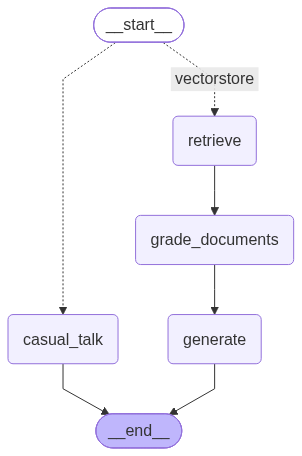

In [25]:
from IPython.display import Image, display

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:
    #  실패 시 통과
    pass


- TEST

In [26]:
inputs = {
    "question": "서울시 자율주행 계획"
}

app.invoke(inputs) # workflow를 실행합니다.

------ROUTE------
---Routing to vectorstore---
------RETRIEVE------
------GRADE------
------GENERATE------


{'question': '서울시 자율주행 계획',
 'generation': AIMessage(content='서울시의 자율주행 계획은 **미래교통 인프라 구축**의 핵심 전략으로, 자율주행차량이 운행할 수 있는 도로·도시환경을 단계적으로 조성하는 것을 목표로 합니다.\n\n### 주요 목표\n- **2030년까지** 간선도로급 이상 도로에서 자율주행이 가능한 도로 인프라 환경 조성\n- **2040년까지** 서울 전역에 자율주행차량 운행 환경 구축\n- 자율주행차량의 **수송 분담률 10% 달성**\n\n### 추진 방향\n1. **도로 인프라 선제 구축**\n   - 자율주행 기술이 도입된 이후 대응하기보다, 개발 단계부터 관련 교통 인프라를 마련합니다.\n   - 기존 교통수단과 자율주행차, 개인형 이동장치(PM) 등이 안전하고 효율적으로 공존할 수 있는 통합 교통체계를 지향합니다.\n\n2. **도시공간 변화에 대응**\n   - 자율주행으로 이동 패턴과 도시 활동이 변화할 가능성에 대비합니다.\n   - 자율주행차량 도입에 따른 도시공간 구조와 교통환경 변화를 고려해 정착 가이드라인을 마련할 필요가 있습니다.\n\n3. **모빌리티 허브 구축**\n   - 서울 전역의 도심 및 광역거점에 기존 대중교통과 미래교통수단을 연결하는 **모빌리티 허브**를 조성합니다.\n   - 모빌리티 허브에는 교통 기능뿐 아니라 공공서비스, 물류, 상업 등 복합 기능을 도입할 계획입니다.\n\n4. **다양한 미래교통수단과 연계**\n   - 자율주행뿐 아니라 도심항공교통(UAM), 개인형 이동장치, 신(新)물류체계 등을 함께 고려하는 다차원 교통체계를 구축합니다.\n   - 이는 보행과 PM 중심의 생활권, 즉 집을 중심으로 업무·소비·여가를 도보 30분 내에 누리는 **보행일상권**과도 연계됩니다.\n\n종합하면, 서울시는 자율주행을 단순히 차량 기술의 도입으로 보지 않고, **도로 인프라·도시공간·대중교통·물류·생활권을 함께 재편하는 도시계획 과제**로 접근하고 있

In [27]:
inputs = {
    "question": "잘 지내고 있어?"
}

app.invoke(inputs) # workflow를 실행합니다.

------ROUTE------
---Routing to casual_talk---
------CASUAL TALK------


{'question': '잘 지내고 있어?',
 'generation': AIMessage(content='응, 잘 지내고 있어! 😊 너는 잘 지내고 있어?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 20, 'prompt_tokens': 12, 'total_tokens': 32, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.6-luna', 'system_fingerprint': None, 'id': 'chatcmpl-Ea1zwxlCYoeNxCfoP10Z4U3KyeGrV', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a14acb-3988-7922-87fd-9c157da18896-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 12, 'output_tokens': 20, 'total_tokens': 32, 'input_token_details': {'audio': 0, 'cache_read': 0, 'cache_creation': 0}, 'output_token_details': {'aud

- 스트림 방식으로 답변 출력

In [28]:
inputs = {
    "question": "서울시의 자율주행 차량 관련 계획은 무엇이 있나요?"
}

for msg, meta in app.stream(inputs, stream_mode='messages'):
    print(msg.content, end='')

------ROUTE------
{"datasource":"vectorstore"}---Routing to vectorstore---
------RETRIEVE------


f:\ksol927_ai_study\StudyRepo\learn_doit_llm_agent\chap13\.venv\Lib\site-packages\pydantic\main.py:520: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `none` - serialized value may not be as expected [field_name='parsed', input_value=RouteQuery(datasource='vectorstore'), input_type=RouteQuery])
  return self.__pydantic_serializer__.to_python(


------GRADE------
{"binary_score":"yes"}

f:\ksol927_ai_study\StudyRepo\learn_doit_llm_agent\chap13\.venv\Lib\site-packages\pydantic\main.py:520: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `none` - serialized value may not be as expected [field_name='parsed', input_value=GradeDocuments(binary_score='yes'), input_type=GradeDocuments])
  return self.__pydantic_serializer__.to_python(


{"binary_score":"no"}

...

{"binary_score":"yes"}

f:\ksol927_ai_study\StudyRepo\learn_doit_llm_agent\chap13\.venv\Lib\site-packages\pydantic\main.py:520: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `none` - serialized value may not be as expected [field_name='parsed', input_value=GradeDocuments(binary_score='yes'), input_type=GradeDocuments])
  return self.__pydantic_serializer__.to_python(


{"binary_score":"yes"}------GENERATE------


f:\ksol927_ai_study\StudyRepo\learn_doit_llm_agent\chap13\.venv\Lib\site-packages\pydantic\main.py:520: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `none` - serialized value may not be as expected [field_name='parsed', input_value=GradeDocuments(binary_score='yes'), input_type=GradeDocuments])
  return self.__pydantic_serializer__.to_python(


서울시는 **2040 서울도시기본계획**에서 자율주행을 미래교통의 핵심 수단으로 보고 다음과 같은 계획을 제시하고 있습니다.

1. **자율주행 운영 기반 단계적 확대**
   - 2030년까지 간선도로급 이상 도로에서 자율주행차량이 운행할 수 있도록 도로 인프라를 조성합니다.
   - 2040년까지 서울 전역에 자율주행 운행 환경을 구축하는 것을 목표로 합니다.
   - 장기적으로 자율주행차량의 **수송 분담률 10%** 달성을 추진합니다.

2. **시범운영 지역 및 서비스 확대**
   - 현재 운영 중인 자율주행 시범지역을 단계적으로 확대합니다.
   - 지역별 특성에 맞춰 자율주행 셔틀, 버스 등 다양한 서비스를 구현합니다.
   - 서울 전역을 연결하는 **자율주행 버스 노선** 설계를 추진합니다.

3. **스마트 도로 인프라 구축**
   - 자율주행에 필요한 도로정밀지도, 교통데이터, 첨단 도로시설 등을 단계적·지속적으로 확충합니다.
   - 자율주행차량과 도로, 교통관제 시스템이 정보를 주고받을 수 있는 빅데이터 플랫폼을 구축합니다.

4. **제도 및 도시계획 기준 개선**
   - 자율주행차 상용화에 맞춰 도시계획시설 기준, 건축법, 주차장법 등 관련 제도의 개선방안을 마련합니다.
   - 기존 교통수단과 자율주행차가 안전하고 효율적으로 공존할 수 있도록 미래 교통수단 정착 가이드라인도 마련할 필요성을 제시하고 있습니다.

5. **모빌리티 허브 및 통합 플랫폼 구축**
   - 서울 전역에 광역·지역·근린 단위의 모빌리티 허브를 조성합니다.
   - 자율주행차를 기존 대중교통, UAM, 마이크로모빌리티 등과 연계해 환승과 물류, 공공·상업 서비스를 제공하는 복합 거점으로 운영합니다.
   - 다양한 교통수단을 통합적으로 관제·운영·관리하는 **통합 모빌리티 플랫폼**을 구축합니다.

즉, 서울시의 계획은 단순히 자율주행차를 도입하는 데 그치지 않고, **도로·데이터·관제 인프라 확충, 자율주행 버스 확대, 관련 제도 정비, 모빌리티 허브